# Join of the dastasets

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut

hd_df = pd.read_csv("../../data/processed/hd.csv")
lab_events_df = pd.read_csv("../../data/processed/lab_events.csv")
micro_bio_df = pd.read_csv("../../data/processed/microbio.csv")

# Make the join between processed datasets

joined_df = pd.merge(hd_df, lab_events_df, on='hadm_id', how='left', suffixes=('_hd', '_le'))

joined_df = pd.merge(
    joined_df,
    micro_bio_df,
    on=['subject_id', 'hadm_id'],
    how='left',
    suffixes=('_joined', '_micro')
)


# Drop ALL duplicate rows (keeps only unique rows)
joined_df = joined_df.drop_duplicates(keep=False).reset_index(drop=True)
print(joined_df['subject_id'].nunique())
joined_df

4392


,subject_id,hadm_id,icd_code,long_title,gender,age,charttime_joined,valuenum,valueuom,flag,...,charttime_micro,spec_type_desc,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag
0,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,198.00,IU/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,0.03,ng/mL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10000980,29654838,I50,Heart failure,F,75.0,2188-01-05 06:56:00,1.20,u,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10000980,29654838,I50,Heart failure,F,75.0,2188-01-05 06:56:00,85.80,sec,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4452131,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,143.00,mg/dL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4452132,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,3.90,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4452133,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,141.00,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4452134,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,NaN,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Filling the missing values for those who did not have a microbio test done
joined_df['spec_type_desc'] = joined_df['spec_type_desc'].fillna(value = "NO_MICROBIO")
joined_df


,subject_id,hadm_id,icd_code,long_title,gender,age,charttime_joined,valuenum,valueuom,flag,...,charttime_micro,spec_type_desc,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag
0,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,198.00,IU/L,0.0,...,NaN,NO_MICROBIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NaN,NO_MICROBIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,0.03,ng/mL,1.0,...,NaN,NO_MICROBIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10000980,29654838,I50,Heart failure,F,75.0,2188-01-05 06:56:00,1.20,u,1.0,...,NaN,NO_MICROBIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10000980,29654838,I50,Heart failure,F,75.0,2188-01-05 06:56:00,85.80,sec,1.0,...,NaN,NO_MICROBIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4452131,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,143.00,mg/dL,1.0,...,NaN,NO_MICROBIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4452132,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,3.90,mEq/L,0.0,...,NaN,NO_MICROBIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4452133,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,141.00,mEq/L,0.0,...,NaN,NO_MICROBIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4452134,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,NaN,ng/mL,0.0,...,NaN,NO_MICROBIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
#If NO_MICROBIO, fill the microbio_test fields 
micro_bio_cols = ['org_name', 'ab_name', 'dilution_text','dilution_comparison','dilution_value', 'interpretation', 'qc_flag']

micro_bio_mask = joined_df['spec_type_desc'] == "NO_MICROBIO"

#Fill orgname with NOT_ORG_DETECTED
joined_df.loc[micro_bio_mask, 'org_name'] = joined_df.loc[micro_bio_mask, 'org_name'].fillna(value = "NO_ORG_DETECTED")

#Fill test_name with NO_TEST_DONE
joined_df.loc[micro_bio_mask, 'test_name'] = joined_df.loc[micro_bio_mask, 'ab_name'].fillna(value = "NO_TEST_DONE")

# Fill ab_name with NO_AB_DETECTED
joined_df.loc[micro_bio_mask, 'ab_name'] = joined_df.loc[micro_bio_mask, 'ab_name'].fillna(value = "NO_AB_DETECTED")

#Fill dilution_text with "-1"
joined_df.loc[micro_bio_mask, 'dilution_text'] = joined_df.loc[micro_bio_mask, 'dilution_text'].fillna(value = "-1")

#Fill dilution_comparison with "="
joined_df.loc[micro_bio_mask, 'dilution_comparison'] = joined_df.loc[micro_bio_mask, 'dilution_comparison'].fillna(value = "=")

#Fill dilution_value with -1
joined_df.loc[micro_bio_mask, 'dilution_value'] = joined_df.loc[micro_bio_mask, 'dilution_value'].fillna(value = -1)

#Fill interpretation with NOT_INTERPRETATION
joined_df.loc[micro_bio_mask, 'interpretation'] = joined_df.loc[micro_bio_mask, 'interpretation'].fillna(value = "NO_INTERPRETATION")

#Fill qc_flag with NOT_QC_FLAG
joined_df.loc[micro_bio_mask, 'qc_flag'] = joined_df.loc[micro_bio_mask, 'qc_flag'].fillna(value = "NOT_QC_FLAG")

print(joined_df['subject_id'].nunique())
joined_df


4392


,subject_id,hadm_id,icd_code,long_title,gender,age,charttime_joined,valuenum,valueuom,flag,...,charttime_micro,spec_type_desc,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag
0,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,198.00,IU/L,0.0,...,NaN,NO_MICROBIO,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NOT_QC_FLAG
1,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NaN,NO_MICROBIO,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NOT_QC_FLAG
2,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,0.03,ng/mL,1.0,...,NaN,NO_MICROBIO,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NOT_QC_FLAG
3,10000980,29654838,I50,Heart failure,F,75.0,2188-01-05 06:56:00,1.20,u,1.0,...,NaN,NO_MICROBIO,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NOT_QC_FLAG
4,10000980,29654838,I50,Heart failure,F,75.0,2188-01-05 06:56:00,85.80,sec,1.0,...,NaN,NO_MICROBIO,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NOT_QC_FLAG
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4452131,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,143.00,mg/dL,1.0,...,NaN,NO_MICROBIO,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NOT_QC_FLAG
4452132,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,3.90,mEq/L,0.0,...,NaN,NO_MICROBIO,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NOT_QC_FLAG
4452133,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,141.00,mEq/L,0.0,...,NaN,NO_MICROBIO,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NOT_QC_FLAG
4452134,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,NaN,ng/mL,0.0,...,NaN,NO_MICROBIO,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NOT_QC_FLAG


## Correlation between the cols

In [5]:
# Getting the correlations
numeric_cols = du.get_numeric_cols(joined_df)
# Pearson correlation
joined_df[numeric_cols].corr("pearson")

,age,valuenum,flag,dilution_value
age,1.000000,-0.000653,0.031984,0.066657
valuenum,-0.000653,1.000000,0.023081,-0.000421
flag,0.031984,0.023081,1.000000,0.007049
dilution_value,0.066657,-0.000421,0.007049,1.000000


In [6]:
# Kendall correlation
joined_df[numeric_cols].corr("kendall")

,age,valuenum,flag,dilution_value
age,1.000000,0.004472,0.029248,0.123879
valuenum,0.004472,1.000000,-0.034033,0.002754
flag,0.029248,-0.034033,1.000000,0.016582
dilution_value,0.123879,0.002754,0.016582,1.000000


In [7]:
# Spearman correlation
joined_df[numeric_cols].corr("spearman")

,age,valuenum,flag,dilution_value
age,1.000000,0.006246,0.033468,0.149869
valuenum,0.006246,1.000000,-0.041626,0.003578
flag,0.033468,-0.041626,1.000000,0.017640
dilution_value,0.149869,0.003578,0.017640,1.000000


## Lab events profile

In [8]:
# Creating the subject profile for lab events (unique admissions)
lab_events_profile = (
    joined_df[['subject_id', 'hadm_id', 'icd_code', 'age', 'gender']]
    .drop_duplicates(subset=['subject_id', 'hadm_id'])
)

# Count unique lab labels per admission
lab_events_count = (
    joined_df.dropna(subset=['label'])
    .groupby(['subject_id', 'hadm_id'])['label']
    .nunique()
    .reset_index(name='unique_lab_labels')
)

# Abnormal flag ratio
abnormal_flag_profile = (
    joined_df.groupby(['subject_id', 'hadm_id'])['flag']
    .apply(lambda s: np.nan if (valid := s.dropna()).empty else valid.eq(1).mean())
    .reset_index(name='abnormal_flag_ratio')
)

lab_events_profile = (
    lab_events_profile
    .merge(lab_events_count, on=['subject_id', 'hadm_id'], how='left')
    .merge(abnormal_flag_profile, on=['subject_id', 'hadm_id'], how='left')
)

# Glucose profile
glucose_mask = joined_df['label'] == 'Glucose'

#For each (subject_id, hadm_id) the max glucose value of the admission
glucose_profile = joined_df[glucose_mask].groupby(['subject_id', 'hadm_id'])['valuenum'].max().reset_index(name='max_glucose_value')

#For each (subject_id, hadm_id) the min glucose value of the admission
glucose_profile_min = joined_df[glucose_mask].groupby(['subject_id', 'hadm_id'])['valuenum'].min().reset_index(name='min_glucose_value')


lab_events_profile = lab_events_profile.merge(glucose_profile, on=['subject_id', 'hadm_id'], how='left')
lab_events_profile = lab_events_profile.merge(glucose_profile_min, on=['subject_id', 'hadm_id'], how='left')

#White Blood Cell Count profile
wbc_mask = joined_df['label'] == 'White Blood Cells'

# For each (subject_id, hadm_id) the max WBC value of the admission
wbc_profile = joined_df[wbc_mask].groupby(['subject_id', 'hadm_id'])['valuenum'].max().reset_index(name='max_wbc_value')

# For each (subject_id, hadm_id) the min WBC value of the admission
wbc_profile_min = joined_df[wbc_mask].groupby(['subject_id', 'hadm_id'])['valuenum'].min().reset_index(name='min_wbc_value')

lab_events_profile = lab_events_profile.merge(wbc_profile, on=['subject_id', 'hadm_id'], how='left')
lab_events_profile = lab_events_profile.merge(wbc_profile_min, on=['subject_id', 'hadm_id'], how='left')

#Platelet Count profile
platelet_mask = joined_df['label'] == 'Platelet Count'

# For each (subject_id, hadm_id) the max Platelet Count value of the admission
platelet_profile = joined_df[platelet_mask].groupby(['subject_id', 'hadm_id'])['valuenum'].max().reset_index(name='max_platelet_value')

# For each (subject_id, hadm_id) the min Platelet Count value of the admission
platelet_profile_min = joined_df[platelet_mask].groupby(['subject_id', 'hadm_id'])['valuenum'].min().reset_index(name='min_platelet_value')

lab_events_profile = lab_events_profile.merge(platelet_profile, on=['subject_id', 'hadm_id'], how='left')
lab_events_profile = lab_events_profile.merge(platelet_profile_min, on=['subject_id', 'hadm_id'], how='left')



lab_events_profile

subject_id   hadm_id icd_code   age gender  num_lab_events  \
0       10000980  26913865      I21  75.0      M             124   
1       10000980  29654838      I50  75.0      F              45   
2       10002013  24760295      I21  69.0      F              40   
3       10002155  23822395      I21  69.0      F            3324   
4       10004457  28723315      I35  66.0      M              21   
...          ...       ...      ...   ...    ...             ...   
4859    19998596  24860241      I48  71.0      F             118   
4860    19998597  23720781      I31  57.0      F             112   
4861    19998598  26940500      I47  69.0      F              40   
4862    19998599  20343031      I30  59.0      M              56   
4863    19998600  21593455      I35  83.0      M             133   

      abnormal_flag_ratio  
0                0.408284  
1                0.408284  
2                0.375000  
3                0.382671  
4                0.285714  
...                   ...  
4859             0.525424  
4860             0.562500  
4861             0.250000  
4862             0.482143  
4863             0.240602  

      max_wbc_value  min_wbc_value  max_platelet_value  min_platelet_value  
0               4.9            4.3               197.0               175.0  
1               6.3            4.3               223.0               180.0  
2               9.0            6.7               263.0               263.0  
3               7.5            4.0               249.0               136.0  
4               6.5            6.5               265.0               265.0  
...             ...            ...                 ...                 ...  
4859            8.4            5.3               218.0               152.0  
4860            6.0            3.0               254.0               183.0  
4861            3.9            3.6               230.0               212.0  
4862            8.9            5.7               177.0               162.0  
4863            7.5            6.0               245.0               184.0  

[4864 rows x 13 columns]

## Patient risk profile

In [9]:
# Build patient-level aggregates with gender preserved
base = (
    joined_df[['subject_id', 'hadm_id', 'age', 'icd_code', 'gender']]
    .drop_duplicates(subset=['subject_id', 'hadm_id'])
)

org_count = (
    joined_df.groupby(['subject_id', 'hadm_id'])['org_name']
    .nunique()
    .reset_index(name='unique_organisms_count')
)

ab_count = (
    joined_df.groupby(['subject_id', 'hadm_id'])['ab_name']
    .nunique()
    .reset_index(name='unique_antibiotics_count')
)

resistance_stats = (
    joined_df[joined_df['interpretation'] == 'R']
    .dropna(subset=['ab_name'])
    .groupby(['subject_id', 'hadm_id'], as_index=False)
    .agg(
        resistant_organism_count=('org_name', 'nunique'),
        resistant_antibiotic_count=('ab_name', 'nunique')
    )
)

abnormal_ratio = (
    joined_df.groupby(['subject_id', 'hadm_id'])['flag']
    .mean()
    .reset_index(name='abnormal_flag_ratio')
)

abnormal_fluids = (
    joined_df[joined_df['flag'] == 1]
    .groupby(['subject_id', 'hadm_id'])
    .agg(
        abnormal_fluid_count=('fluid', 'nunique'),
        fluids_analyzed=('fluid', lambda x: ', '.join(sorted(x.unique())))
    )
    .reset_index()
)

risk_profile = (
    base.merge(org_count, on=['subject_id', 'hadm_id'], how='left')
        .merge(ab_count, on=['subject_id', 'hadm_id'], how='left')
        .merge(resistance_stats, on=['subject_id', 'hadm_id'], how='left')
        .merge(abnormal_ratio, on=['subject_id', 'hadm_id'], how='left')
        .merge(abnormal_fluids, on=['subject_id', 'hadm_id'], how='left')
)

risk_profile = risk_profile.drop_duplicates(['subject_id', 'hadm_id'])
risk_profile.to_csv("../../data/profiles/risk_profile.csv")

risk_profile

,subject_id,hadm_id,age,icd_code,gender,unique_organisms_count,unique_antibiotics_count,resistant_organism_count,resistant_antibiotic_count,abnormal_flag_ratio,abnormal_fluid_count,fluids_analyzed
0,10000980,29654838,75.0,I50,F,1,1,NaN,NaN,0.400000,1.0,Blood
1,10000980,26913865,75.0,I21,M,1,1,NaN,NaN,0.411290,1.0,Blood
2,10002013,24760295,69.0,I21,F,1,1,NaN,NaN,0.375000,1.0,Blood
3,10002155,23822395,69.0,I21,F,1,1,NaN,NaN,0.382671,1.0,Blood
4,10004457,28723315,66.0,I35,M,1,1,NaN,NaN,0.285714,1.0,Blood
...,...,...,...,...,...,...,...,...,...,...,...,...
4859,19998596,24860241,71.0,I48,F,1,1,NaN,NaN,0.525424,1.0,Blood
4860,19998597,23720781,57.0,I31,F,1,1,NaN,NaN,0.562500,1.0,Blood
4861,19998598,26940500,69.0,I47,F,1,1,NaN,NaN,0.250000,1.0,Blood
4862,19998599,20343031,59.0,I30,M,1,1,NaN,NaN,0.482143,1.0,Blood


## MicroBio patient Profile

In [30]:
micro_bio_profile = (
    joined_df[['subject_id', 'hadm_id', 'icd_code', 'age', 'gender']]
    .drop_duplicates(subset=['subject_id', 'hadm_id'])
)

# Intermediate stats
intermediate_mask = (
    joined_df['interpretation'] == 'I'
)

intermediate_df = joined_df[intermediate_mask]

intermediate_org_counts = (
    intermediate_df
                .groupby(['subject_id', 'hadm_id'])['org_name']
                .nunique()
                .reset_index(name = 'I_organism_count')
)

micro_bio_profile = micro_bio_profile.merge(
    intermediate_org_counts, 
    on=['subject_id', 'hadm_id'],
    how="left"
)

# Fill NaN with 0 for intermediate counts
micro_bio_profile['I_organism_count'] = micro_bio_profile['I_organism_count'].fillna(0)

# Resistant stats
resistant_mask = (
    joined_df['interpretation'] == 'R'
)

resistant_df = joined_df[resistant_mask]

resistant_org_counts = (
    resistant_df
                .groupby(['subject_id', 'hadm_id'])['org_name']
                .nunique()
                .reset_index(name = 'R_organism_count')
)

micro_bio_profile = micro_bio_profile.merge(
    resistant_org_counts,
    on=['subject_id', 'hadm_id'],
    how='left'
)

# Fill NaN with 0 for resistant counts
micro_bio_profile['R_organism_count'] = micro_bio_profile['R_organism_count'].fillna(0)

# Sensitive stats
sensitive_mask = (
    joined_df['interpretation'] == 'S'
)

sensitive_df = joined_df[sensitive_mask]

sensitive_org_counts = (
    sensitive_df
                .groupby(['subject_id', 'hadm_id'])['org_name']
                .nunique()
                .reset_index(name = 'S_organism_count')
)

micro_bio_profile = micro_bio_profile.merge(
    sensitive_org_counts,
    on=['subject_id', 'hadm_id'],
    how='left'
)

micro_bio_profile['S_organism_count'] = micro_bio_profile['S_organism_count'].fillna(0)

ab_count= (
    joined_df.groupby(['subject_id', 'hadm_id'])['ab_name']
    .nunique()
    .reset_index(name='unique_antibiotic_count')
)

micro_bio_profile = micro_bio_profile.merge(
    ab_count,
    on=['subject_id', 'hadm_id'],
    how='left'
)
micro_bio_profile

,subject_id,hadm_id,icd_code,age,gender,I_organism_count,R_organism_count,S_organism_count,unique_antibiotic_count
0,10000980,29654838,I50,75.0,F,0.0,0.0,0.0,1
1,10000980,26913865,I21,75.0,M,0.0,0.0,0.0,1
2,10002013,24760295,I21,69.0,F,0.0,0.0,0.0,1
3,10002155,23822395,I21,69.0,F,0.0,0.0,0.0,1
4,10004457,28723315,I35,66.0,M,0.0,0.0,0.0,1
...,...,...,...,...,...,...,...,...,...
4859,19998596,24860241,I48,71.0,F,0.0,0.0,0.0,1
4860,19998597,23720781,I31,57.0,F,0.0,0.0,0.0,1
4861,19998598,26940500,I47,69.0,F,0.0,0.0,0.0,1
4862,19998599,20343031,I30,59.0,M,0.0,0.0,0.0,1


## MicroBio patient profile

## Visual exploration
The following plots give a quick overview of age distribution in the cohort, the tests with the highest abnormal rates, and how resistance relates to antibiotic coverage.

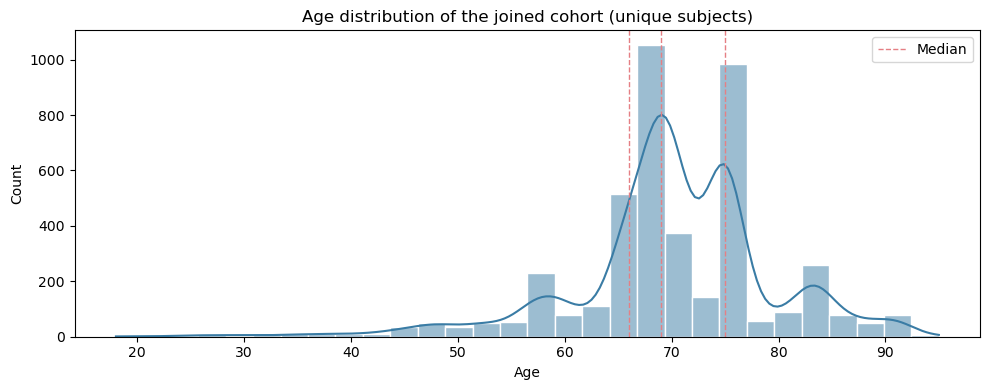

In [11]:
# Age distribution with KDE overlay and highlighted quartiles (unique subjects)
unique_subject_age = (
    joined_df[['subject_id', 'age']]
    .dropna(subset=['age'])
    .drop_duplicates(subset='subject_id')
)

plt.figure(figsize=(10, 4))
sns.histplot(
    data=unique_subject_age,
    x='age',
    bins=30,
    kde=True,
    color='#3A7CA5',
    edgecolor='white'
)
q1, q2, q3 = unique_subject_age['age'].quantile([0.25, 0.5, 0.75])
for q, label in zip([q1, q2, q3], ['Q1', 'Median', 'Q3']):
    plt.axvline(q, color='#E57F84', linestyle='--', linewidth=1, label=label if label == 'Median' else None)
plt.title('Age distribution of the joined cohort (unique subjects)')
plt.xlabel('Age')
plt.ylabel('Count')
plt.legend(loc='upper right')
plt.tight_layout()

## Sex distribution per ICD code

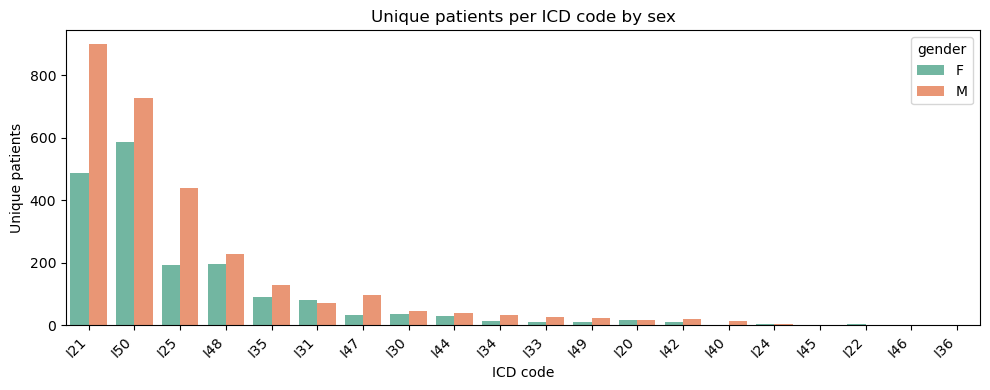

In [12]:
counts = (
    joined_df.groupby(['icd_code', 'gender'])['subject_id']
    .nunique()
    .reset_index(name='unique_patients')
)

icd_order = (
    counts.groupby('icd_code')['unique_patients']
    .sum()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(10, 4))
sns.barplot(
    data=counts,
    x='icd_code',
    y='unique_patients',
    hue='gender',
    palette='Set2',
    order=icd_order
)
plt.title('Unique patients per ICD code by sex')
plt.xlabel('ICD code')
plt.ylabel('Unique patients')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

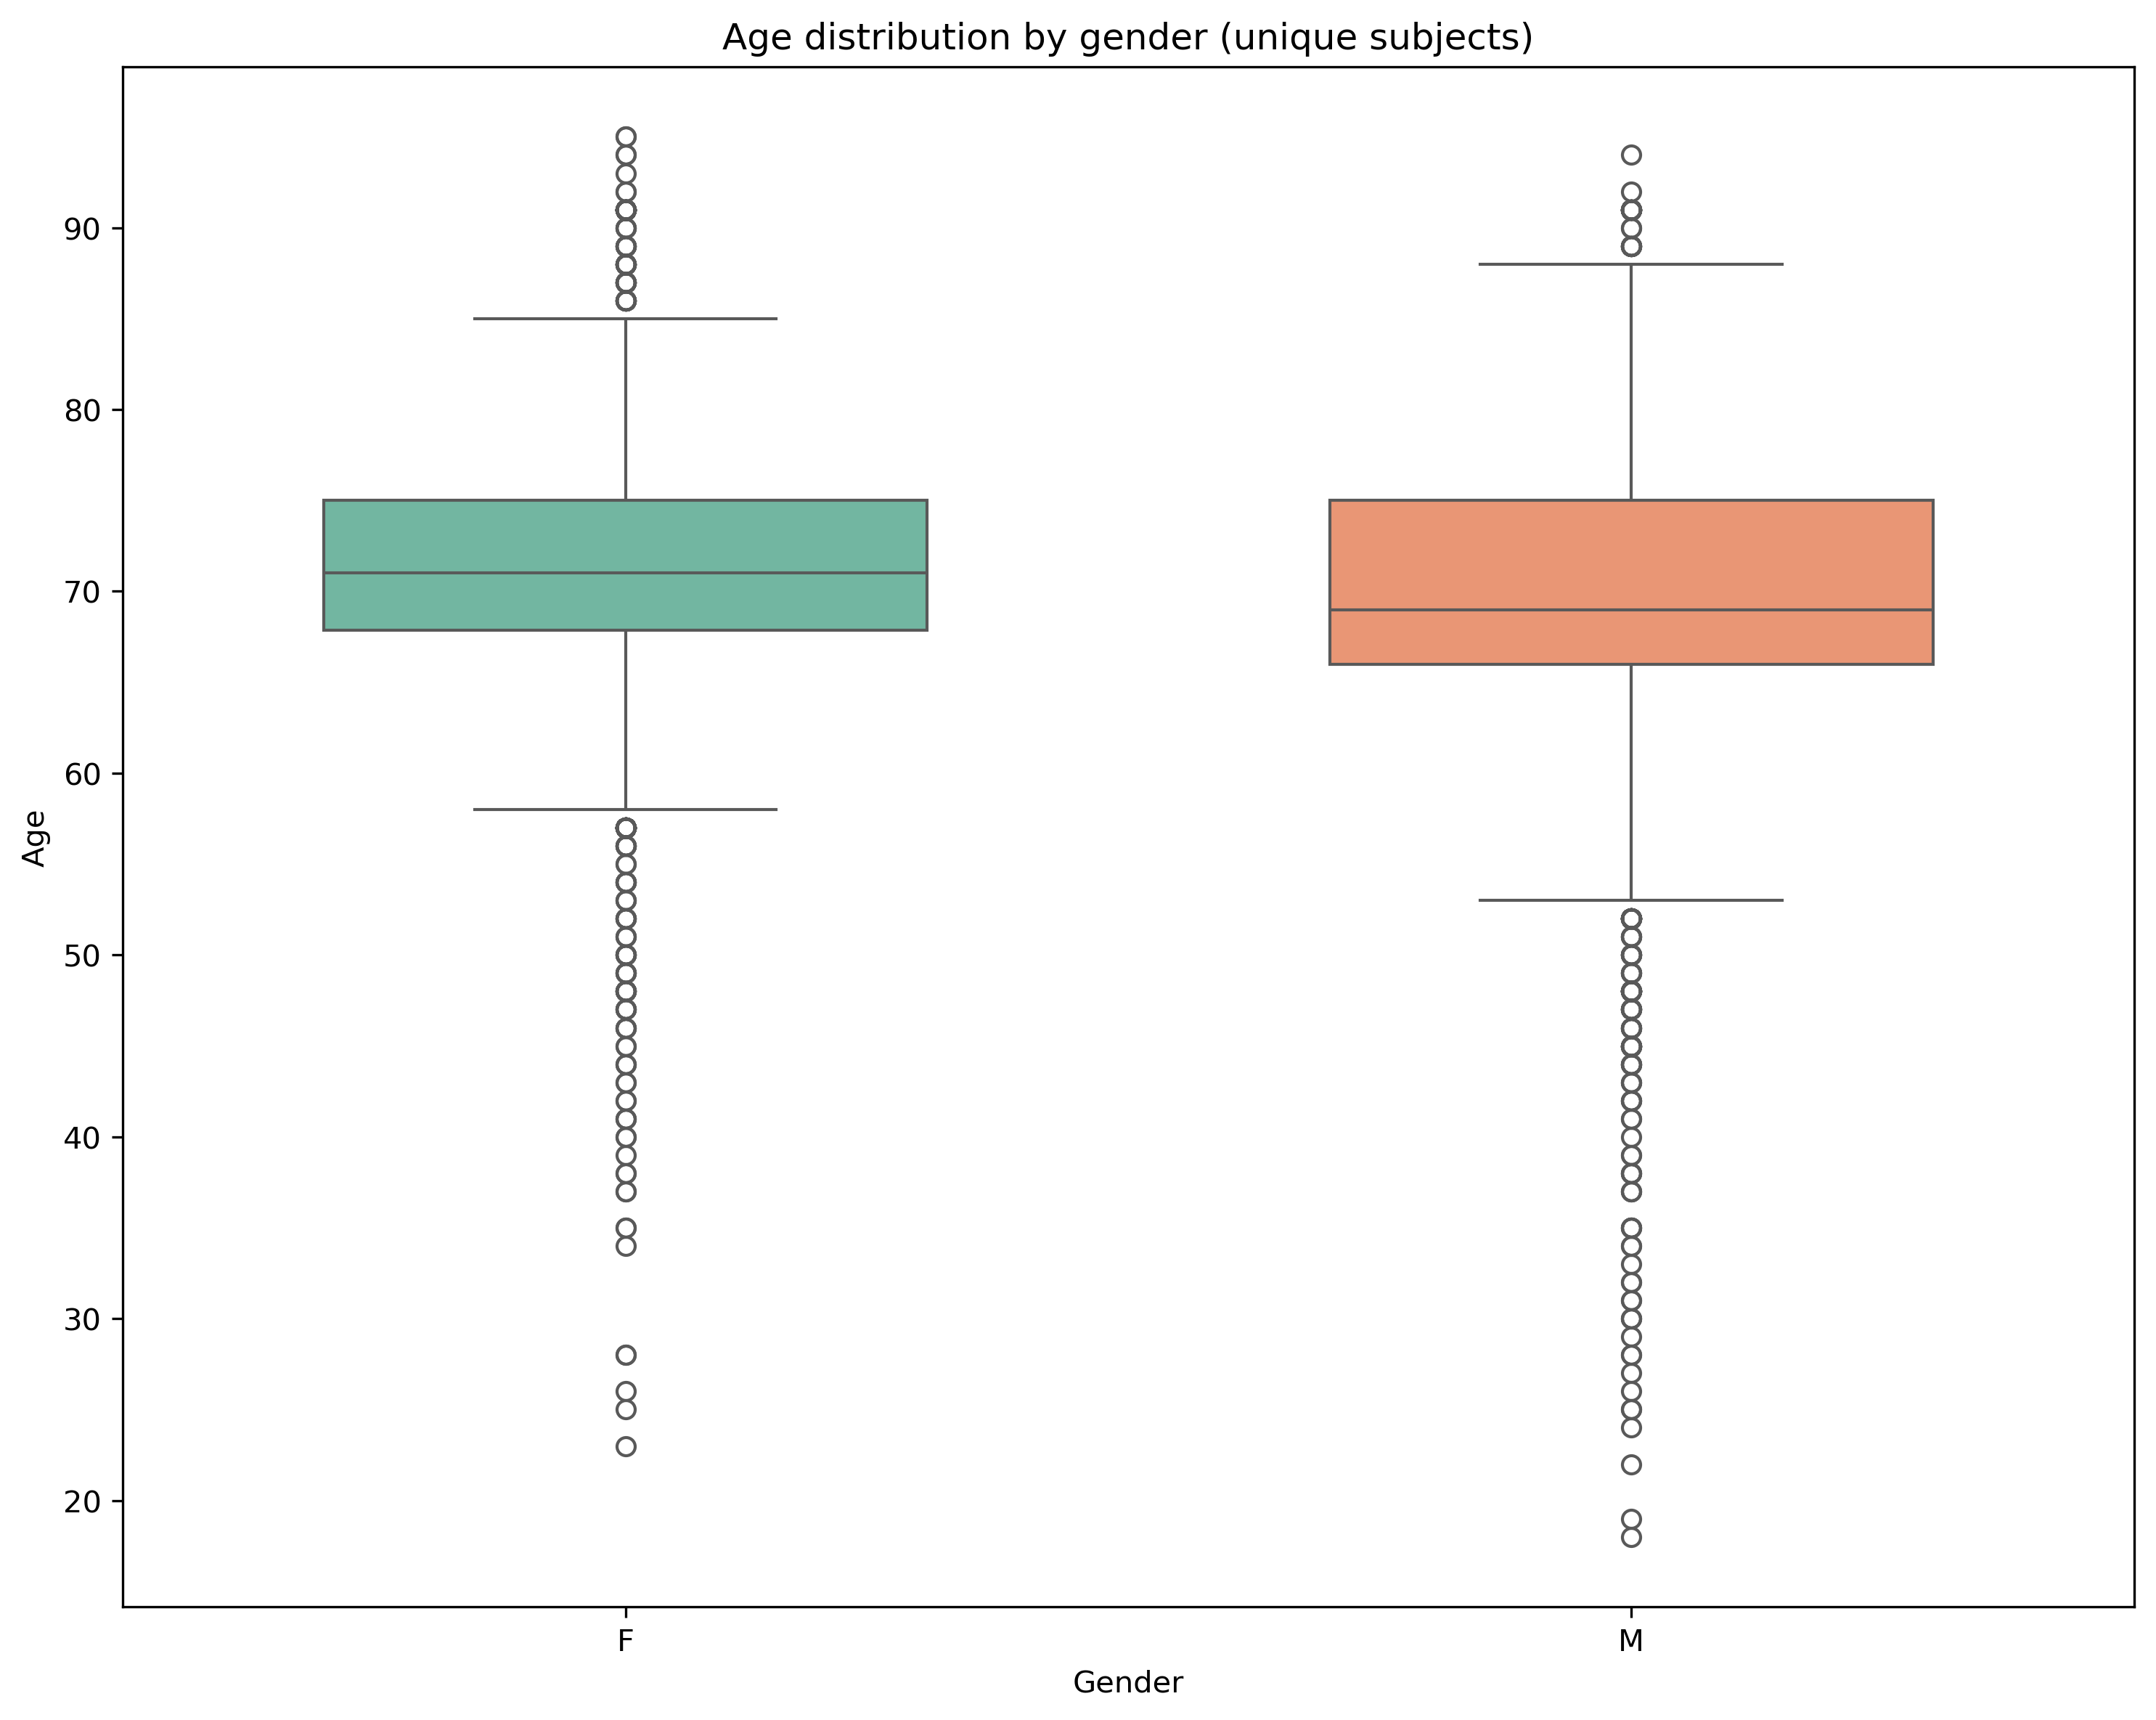

In [13]:
subject_age = (
    joined_df[['subject_id', 'gender', 'age']]
    .dropna(subset=['gender', 'age'])
    .drop_duplicates(subset='subject_id')
)

plt.figure(figsize=(10, 8), dpi=300)
sns.boxplot(
    data=subject_age,
    x='gender',
    y='age',
    hue='gender',
    palette='Set2',
    width=0.6,
    dodge=False,
    legend=False
)
plt.title('Age distribution by gender (unique subjects)')
plt.xlabel('Gender')
plt.ylabel('Age')
plt.tight_layout()

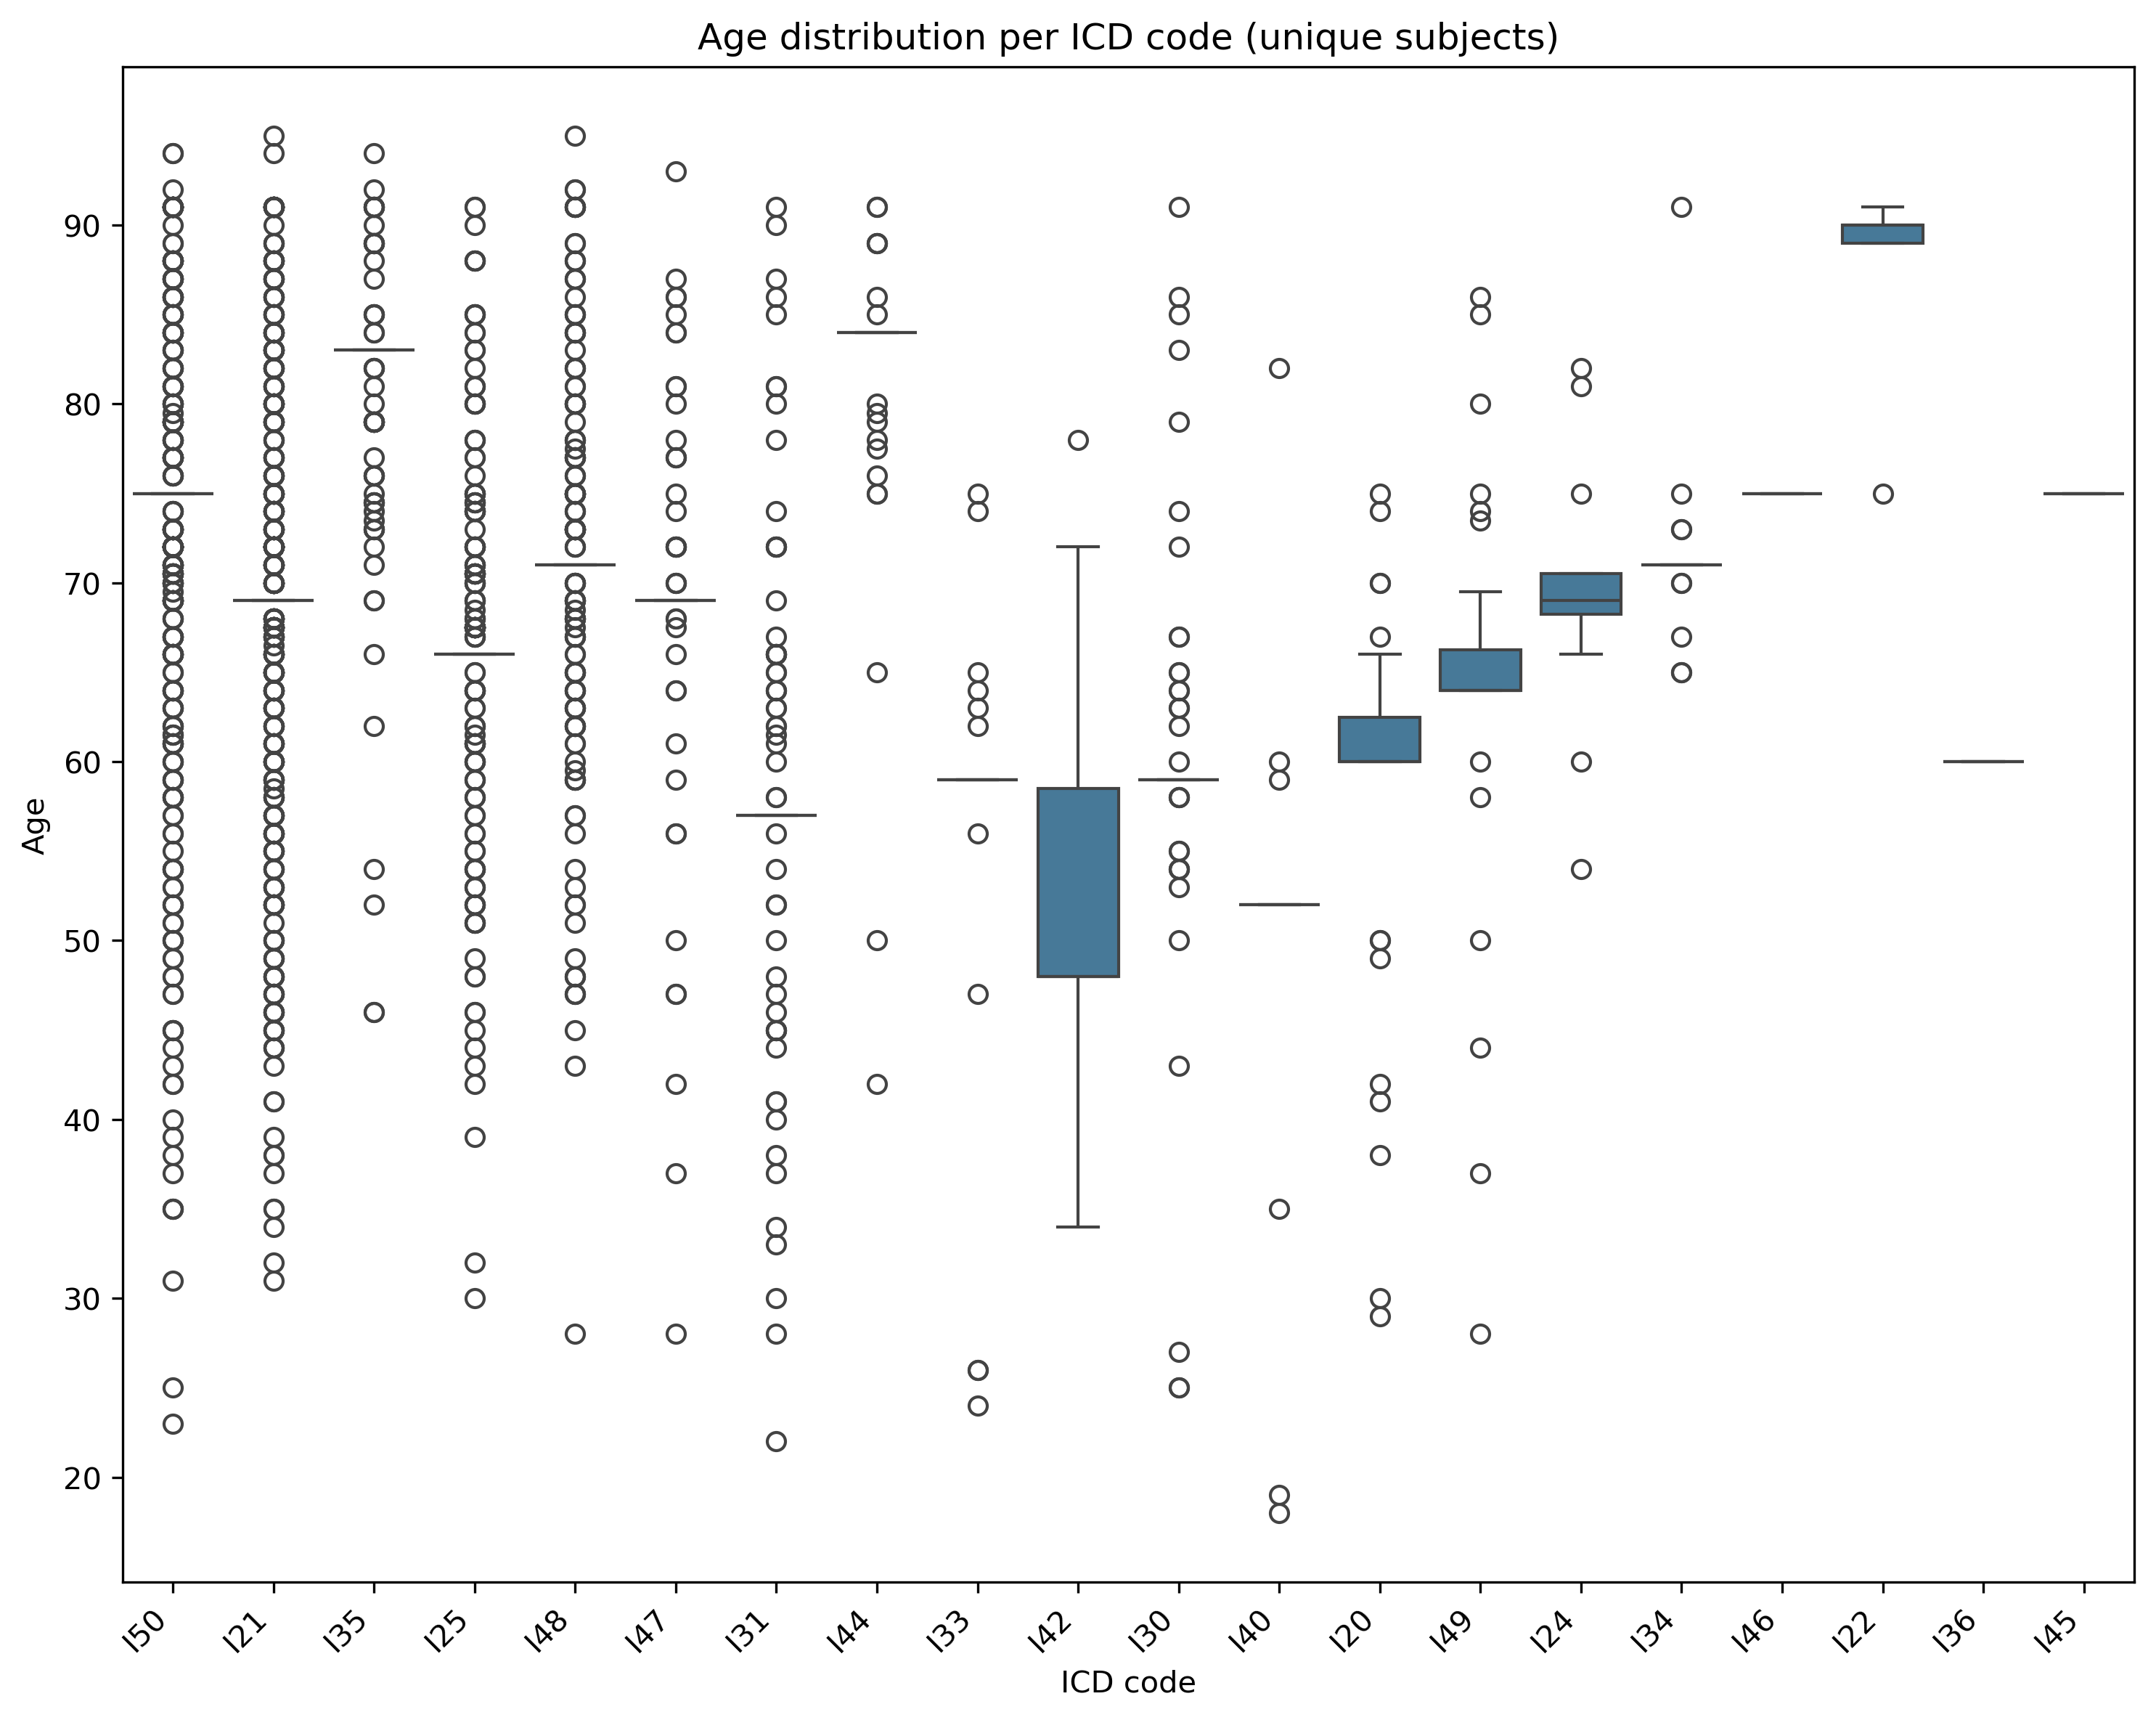

In [14]:
#to visualize for each icd_code the age of the patient 
icd_age = (
    joined_df[['subject_id', 'icd_code', 'age']]
    .dropna(subset=['icd_code', 'age'])
    .drop_duplicates(subset=['subject_id', 'icd_code'])
)

plt.figure(figsize=(10, 8), dpi=300)
sns.boxplot(
    data=icd_age,
    x='icd_code',
    y='age',
    color='#3A7CA5'
)
plt.title('Age distribution per ICD code (unique subjects)')
plt.xlabel('ICD code')
plt.ylabel('Age')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

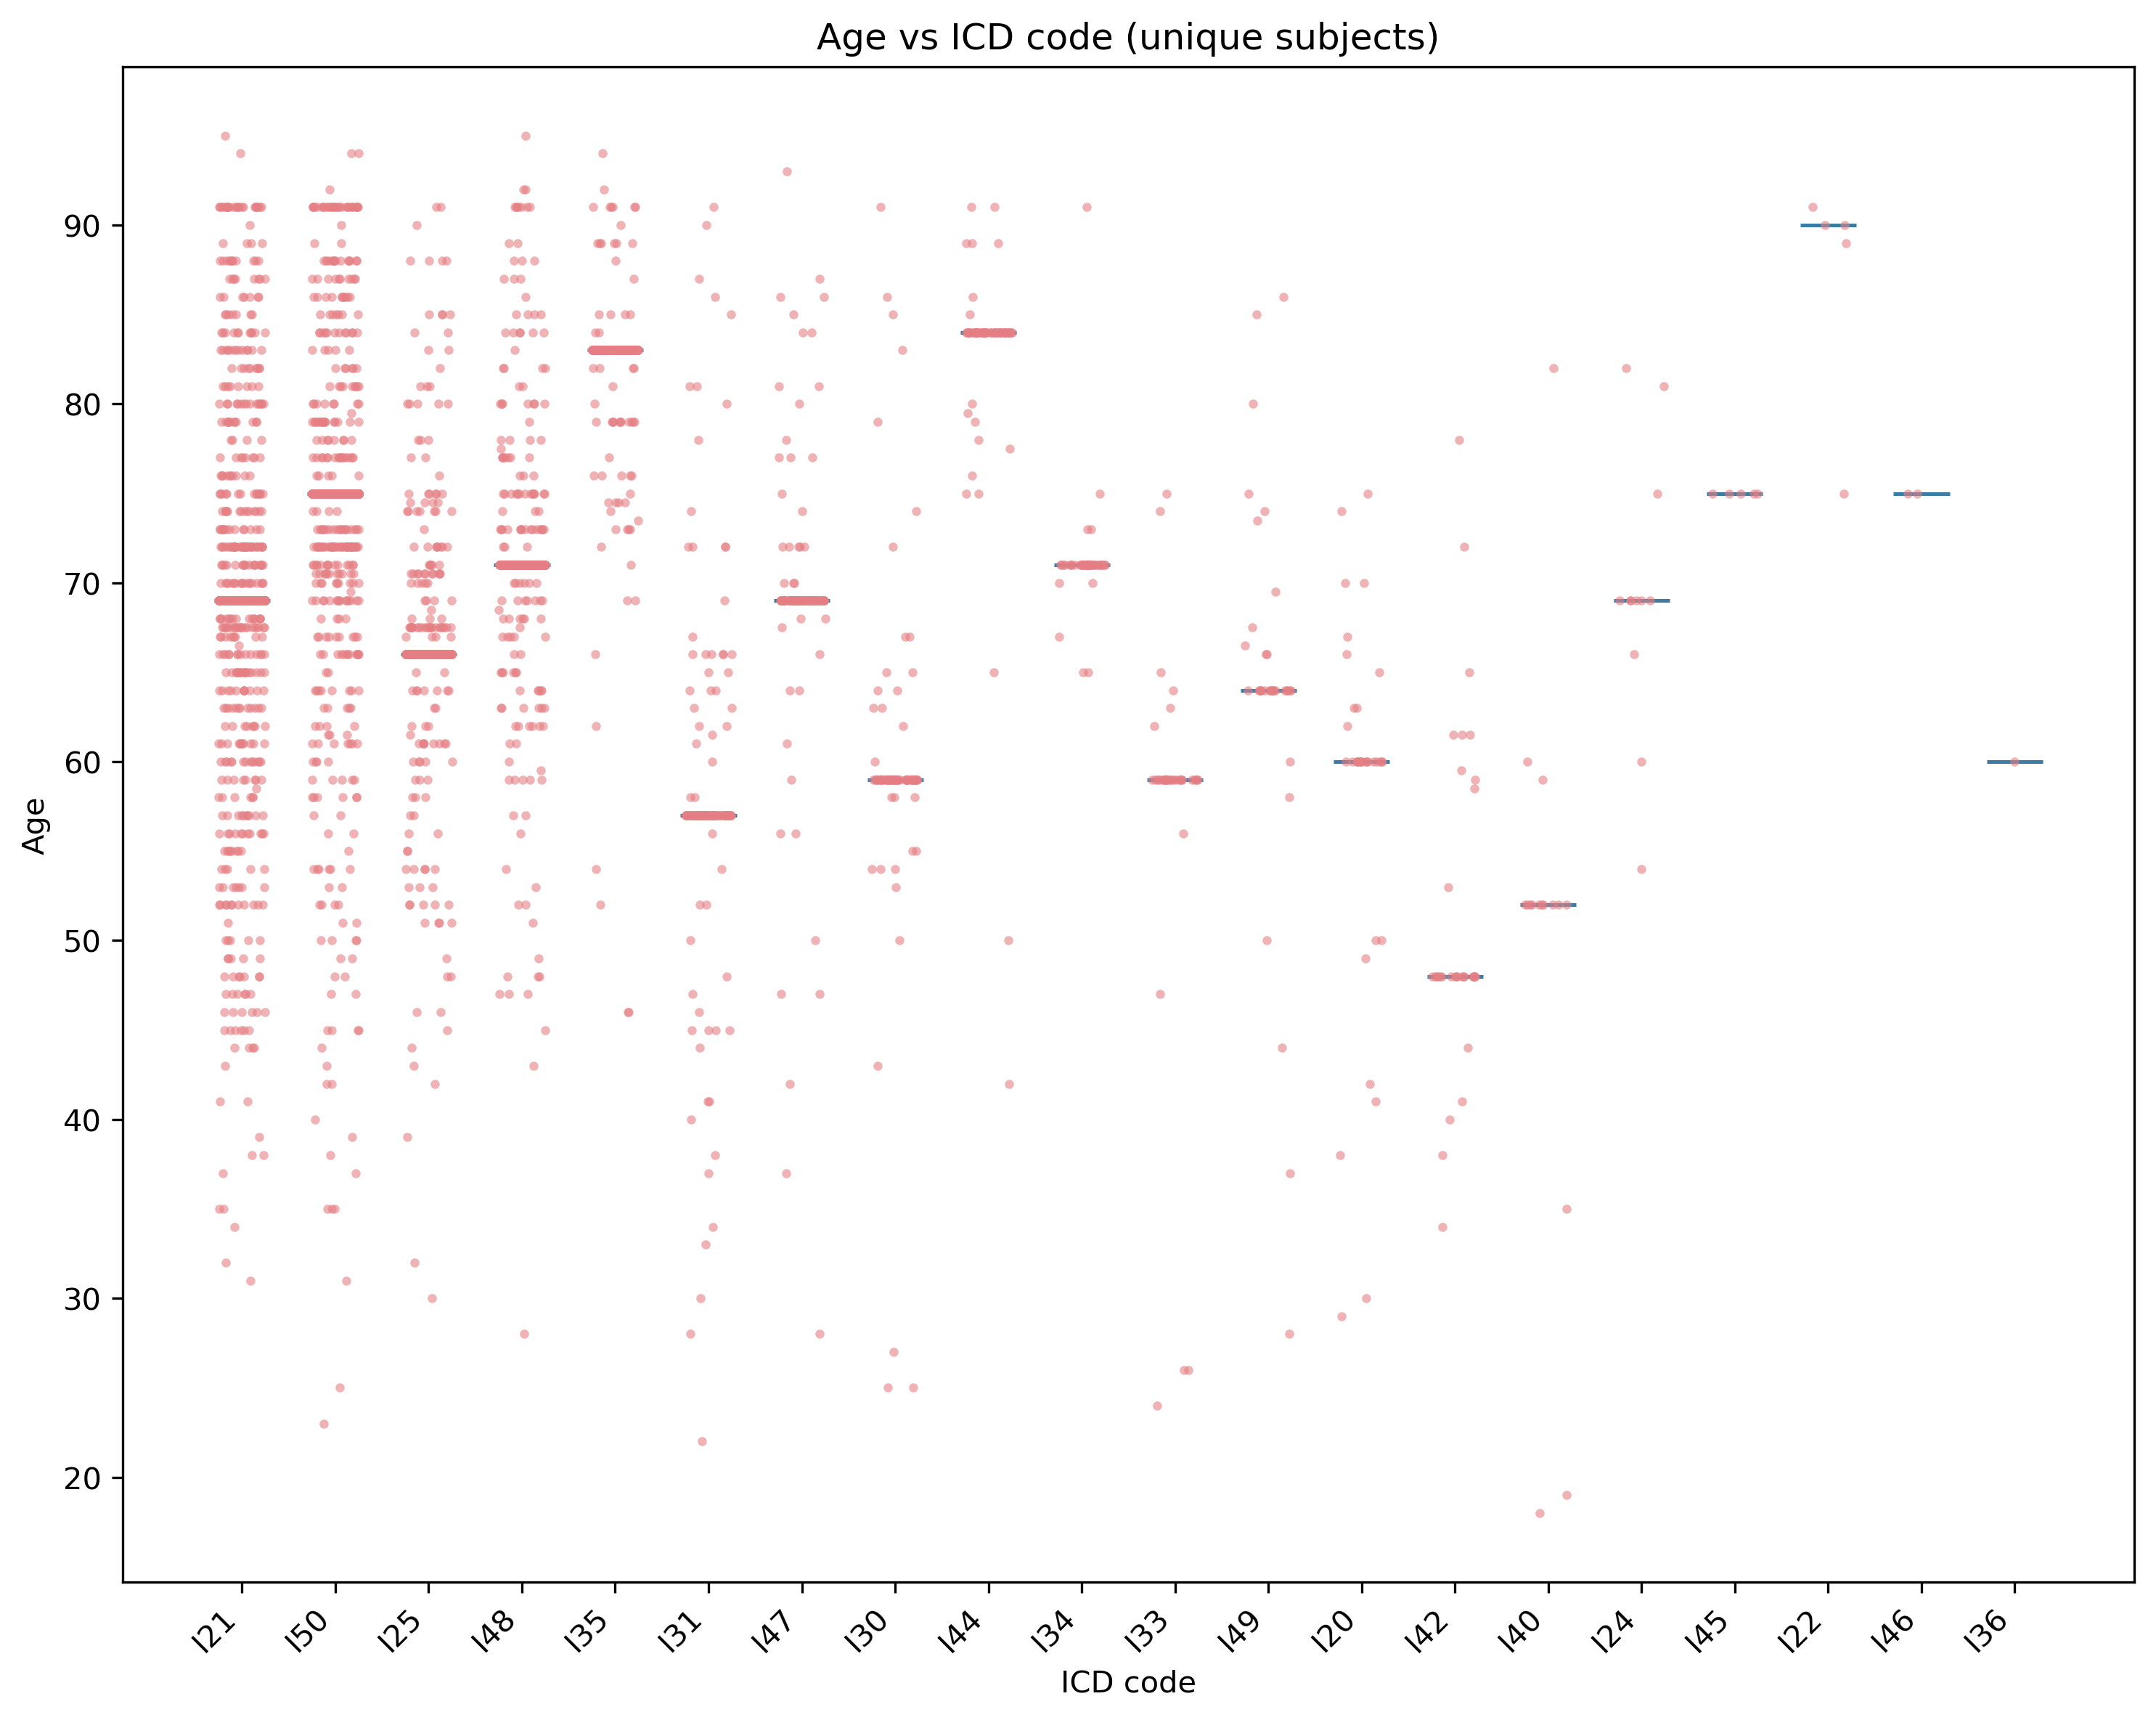

In [15]:
icd_order = (
    icd_age.groupby('icd_code')['subject_id']
    .nunique()
    .sort_values(ascending=False)
    .index
)

median_age_by_icd = (
    icd_age.groupby('icd_code')['age']
    .median()
    .reindex(icd_order)
)

plt.figure(figsize=(10, 8), dpi=300)
sns.stripplot(
    data=icd_age,
    x='icd_code',
    y='age',
    order=icd_order,
    color='#E57F84',
    jitter=0.25,
    size=3,
    alpha=0.6
)

for idx, age in enumerate(median_age_by_icd):
    plt.hlines(age, idx - 0.3, idx + 0.3, color='#3A7CA5', linewidth=1.2)

plt.title('Age vs ICD code (unique subjects)')
plt.xlabel('ICD code')
plt.ylabel('Age')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

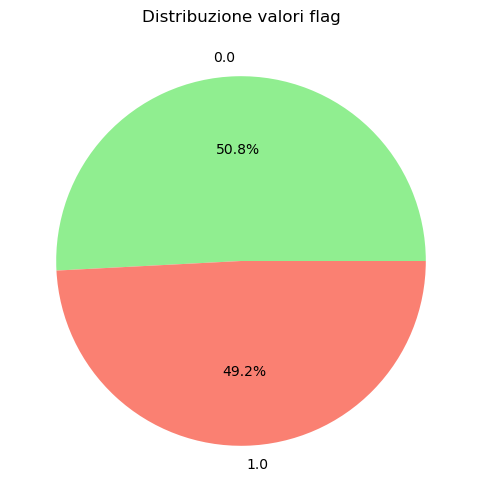

In [16]:
# Prima conta i valori della colonna flag
counts = joined_df['flag'].value_counts().sort_index()

# Poi crea il grafico a torta
plt.figure(figsize=(8, 6))
plt.pie(counts.values, 
        labels=counts.index,  # oppure ['Normale', 'Anormale']
        autopct='%1.1f%%',
        colors=['lightgreen', 'salmon'])
plt.title('Distribuzione valori flag')
plt.show()

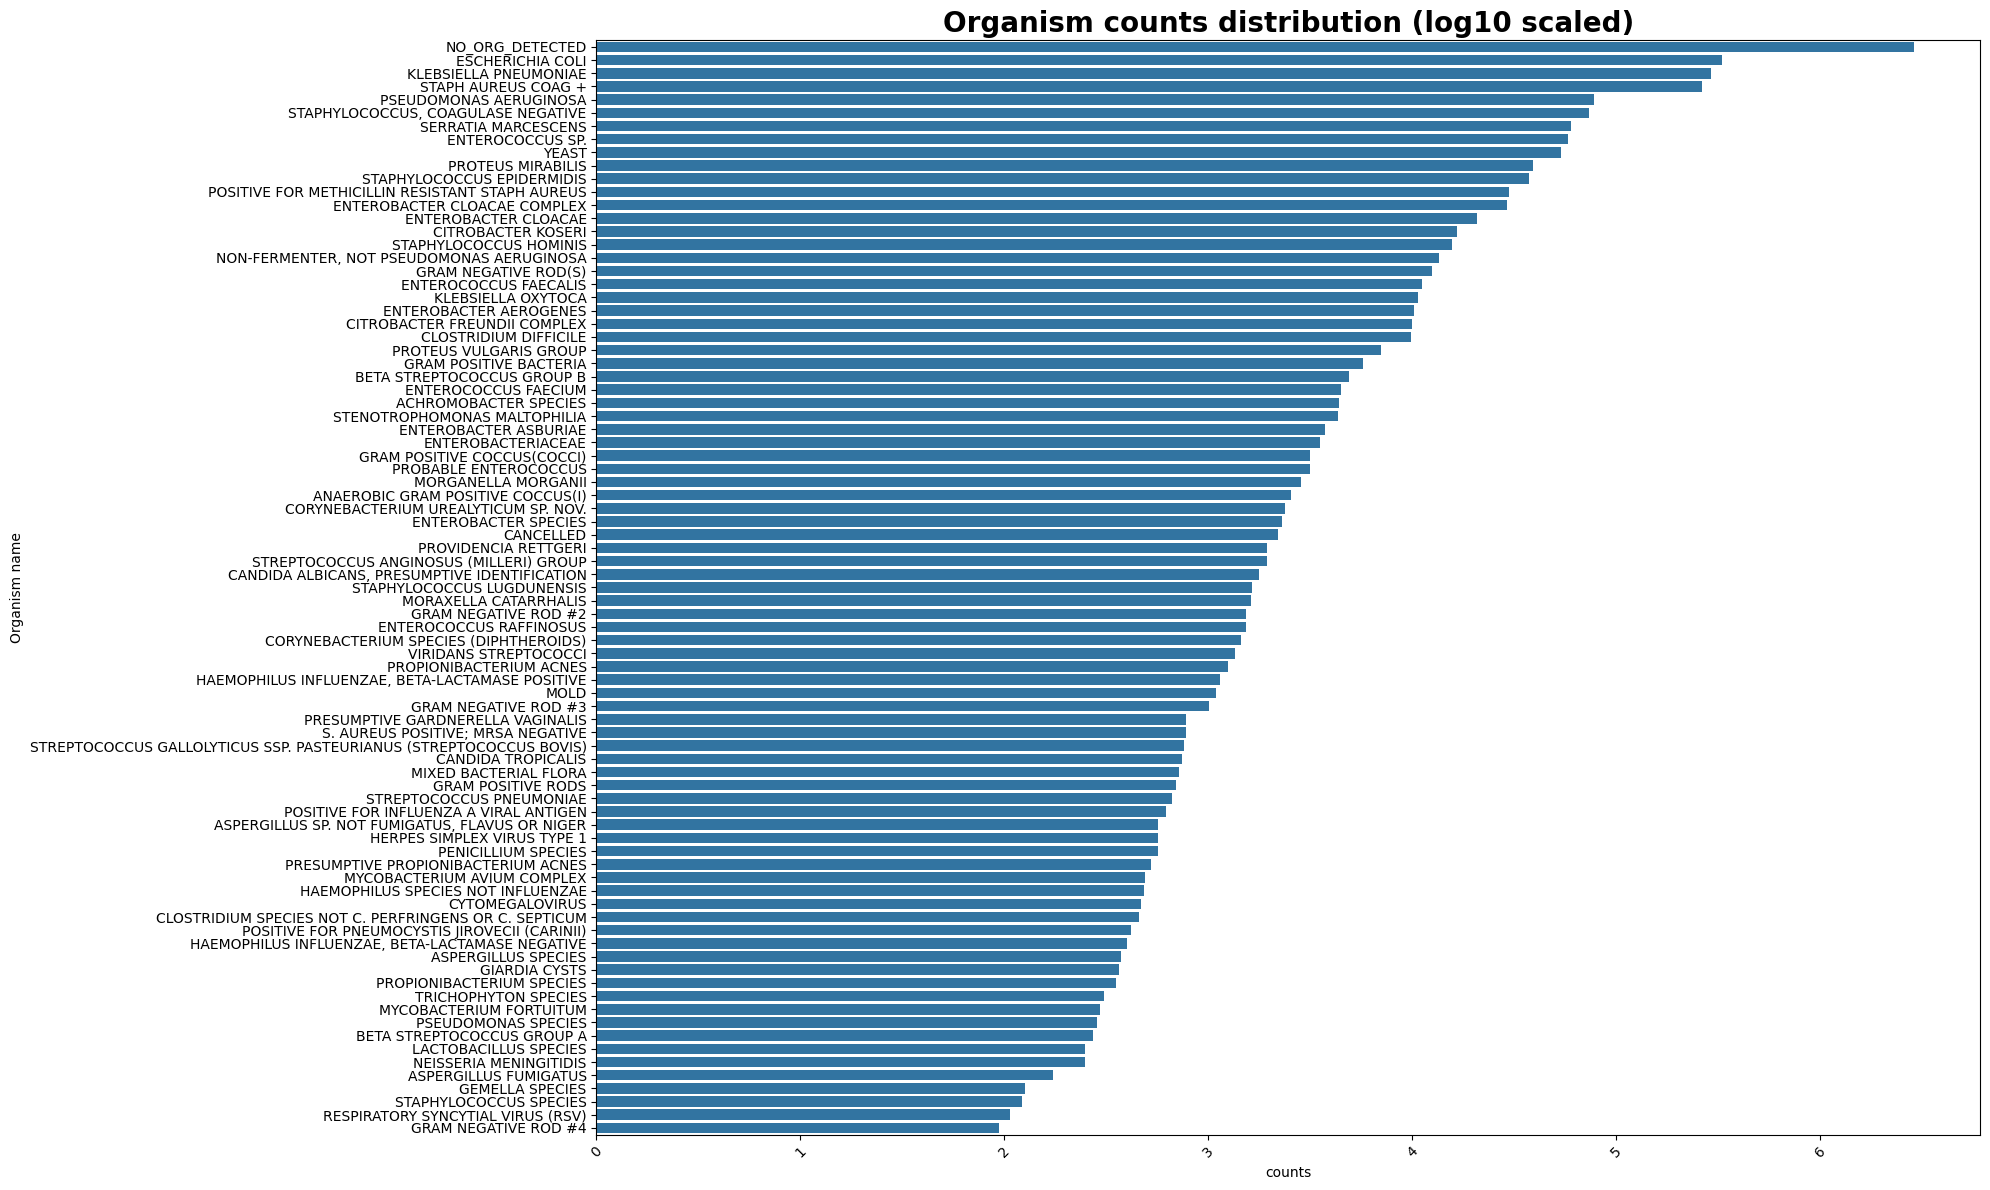

In [17]:
org_count = np.log10(joined_df['org_name'].value_counts().replace(0, np.nan))

plt.figure(figsize=(20, 12))
sns.barplot(y=org_count.index, x=org_count.values)
plt.title("Organism counts distribution (log10 scaled)", fontsize=20, fontweight="bold")
plt.ylabel("Organism name")
plt.xlabel("counts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

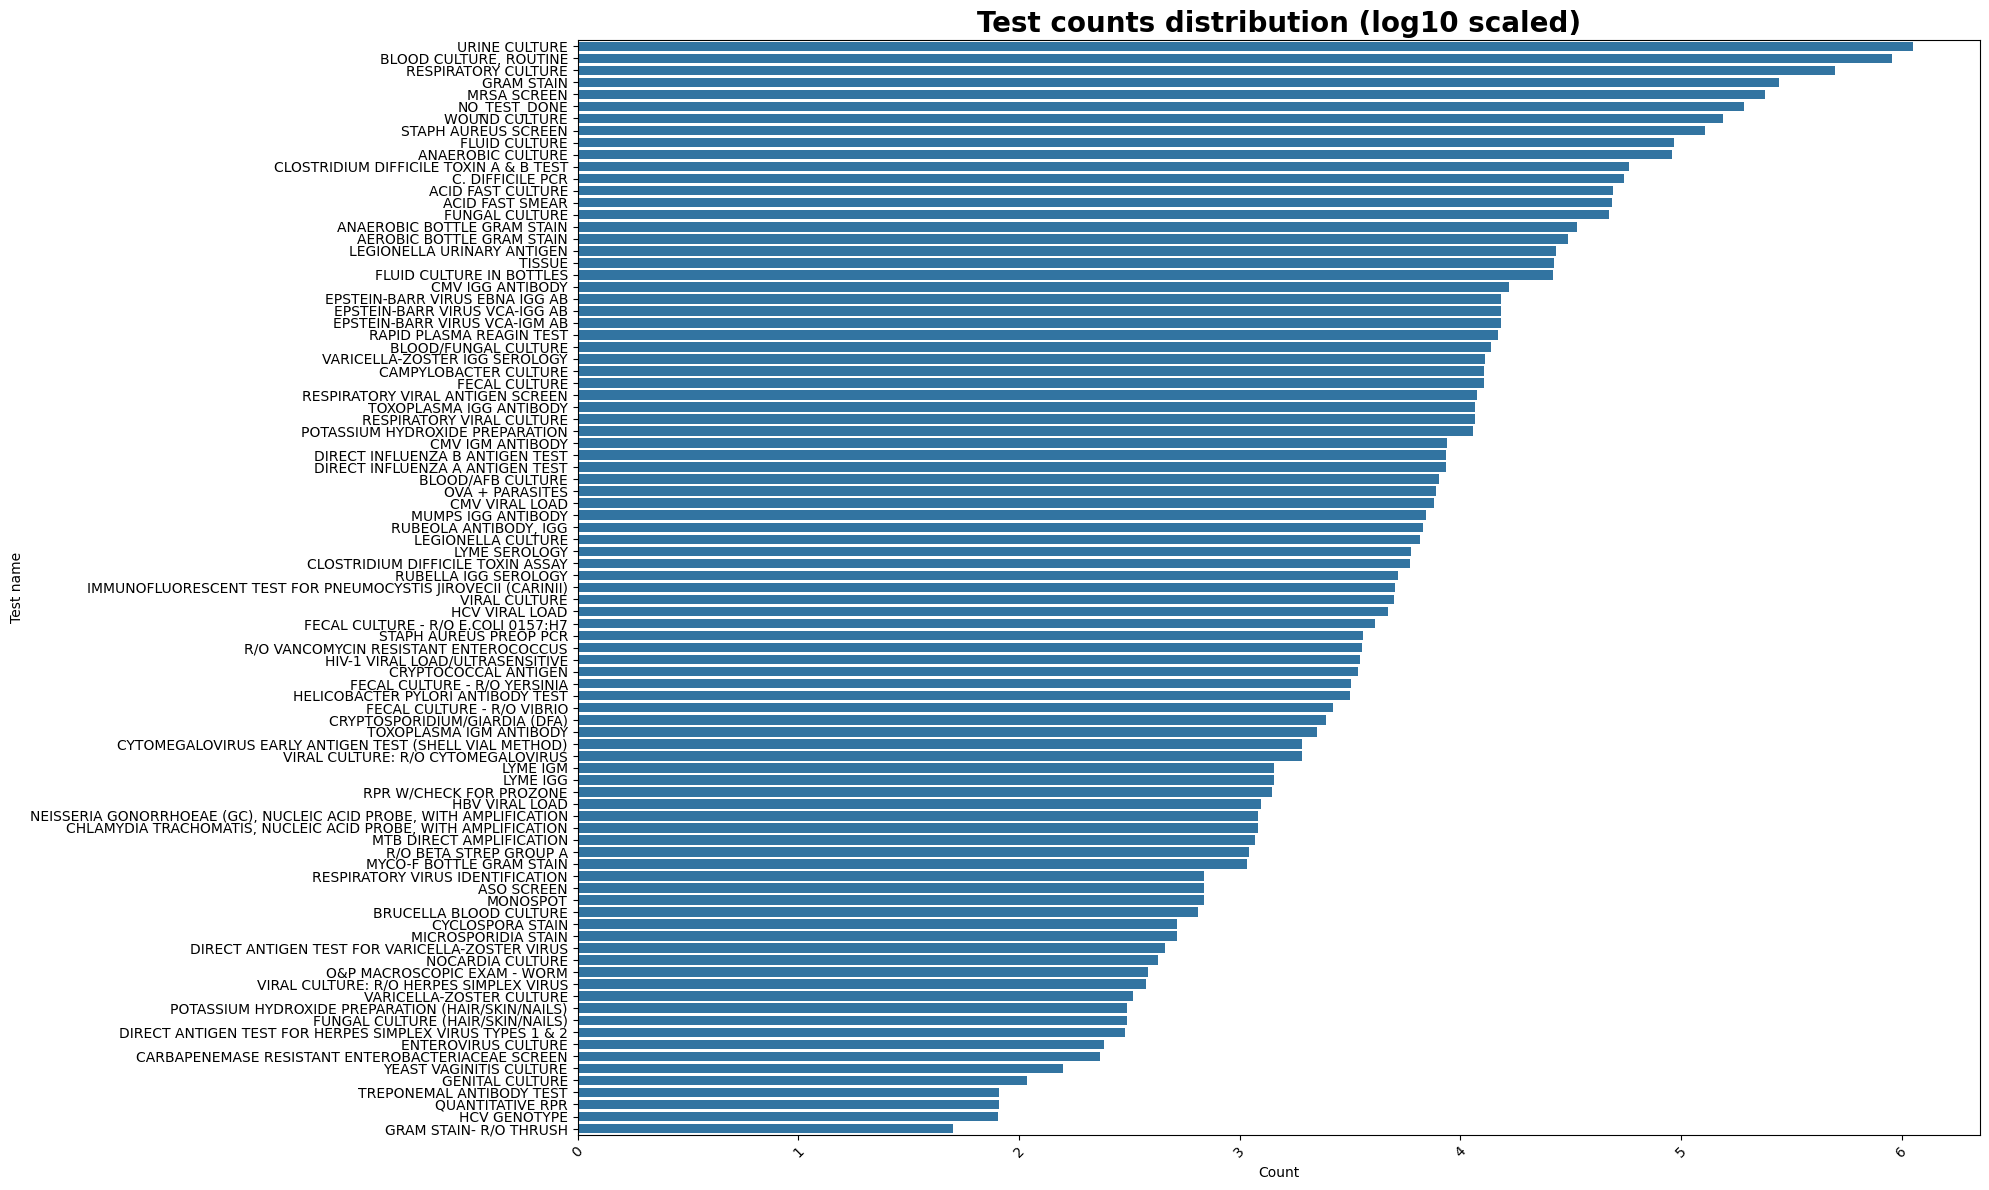

In [18]:
test_count = np.log10(joined_df['test_name'].value_counts().replace(0, np.nan))

plt.figure(figsize=(20, 12))
sns.barplot(y=test_count.index, x=test_count.values)
plt.title("Test counts distribution (log10 scaled)", fontsize=20, fontweight="bold")
plt.ylabel("Test name")
plt.xlabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

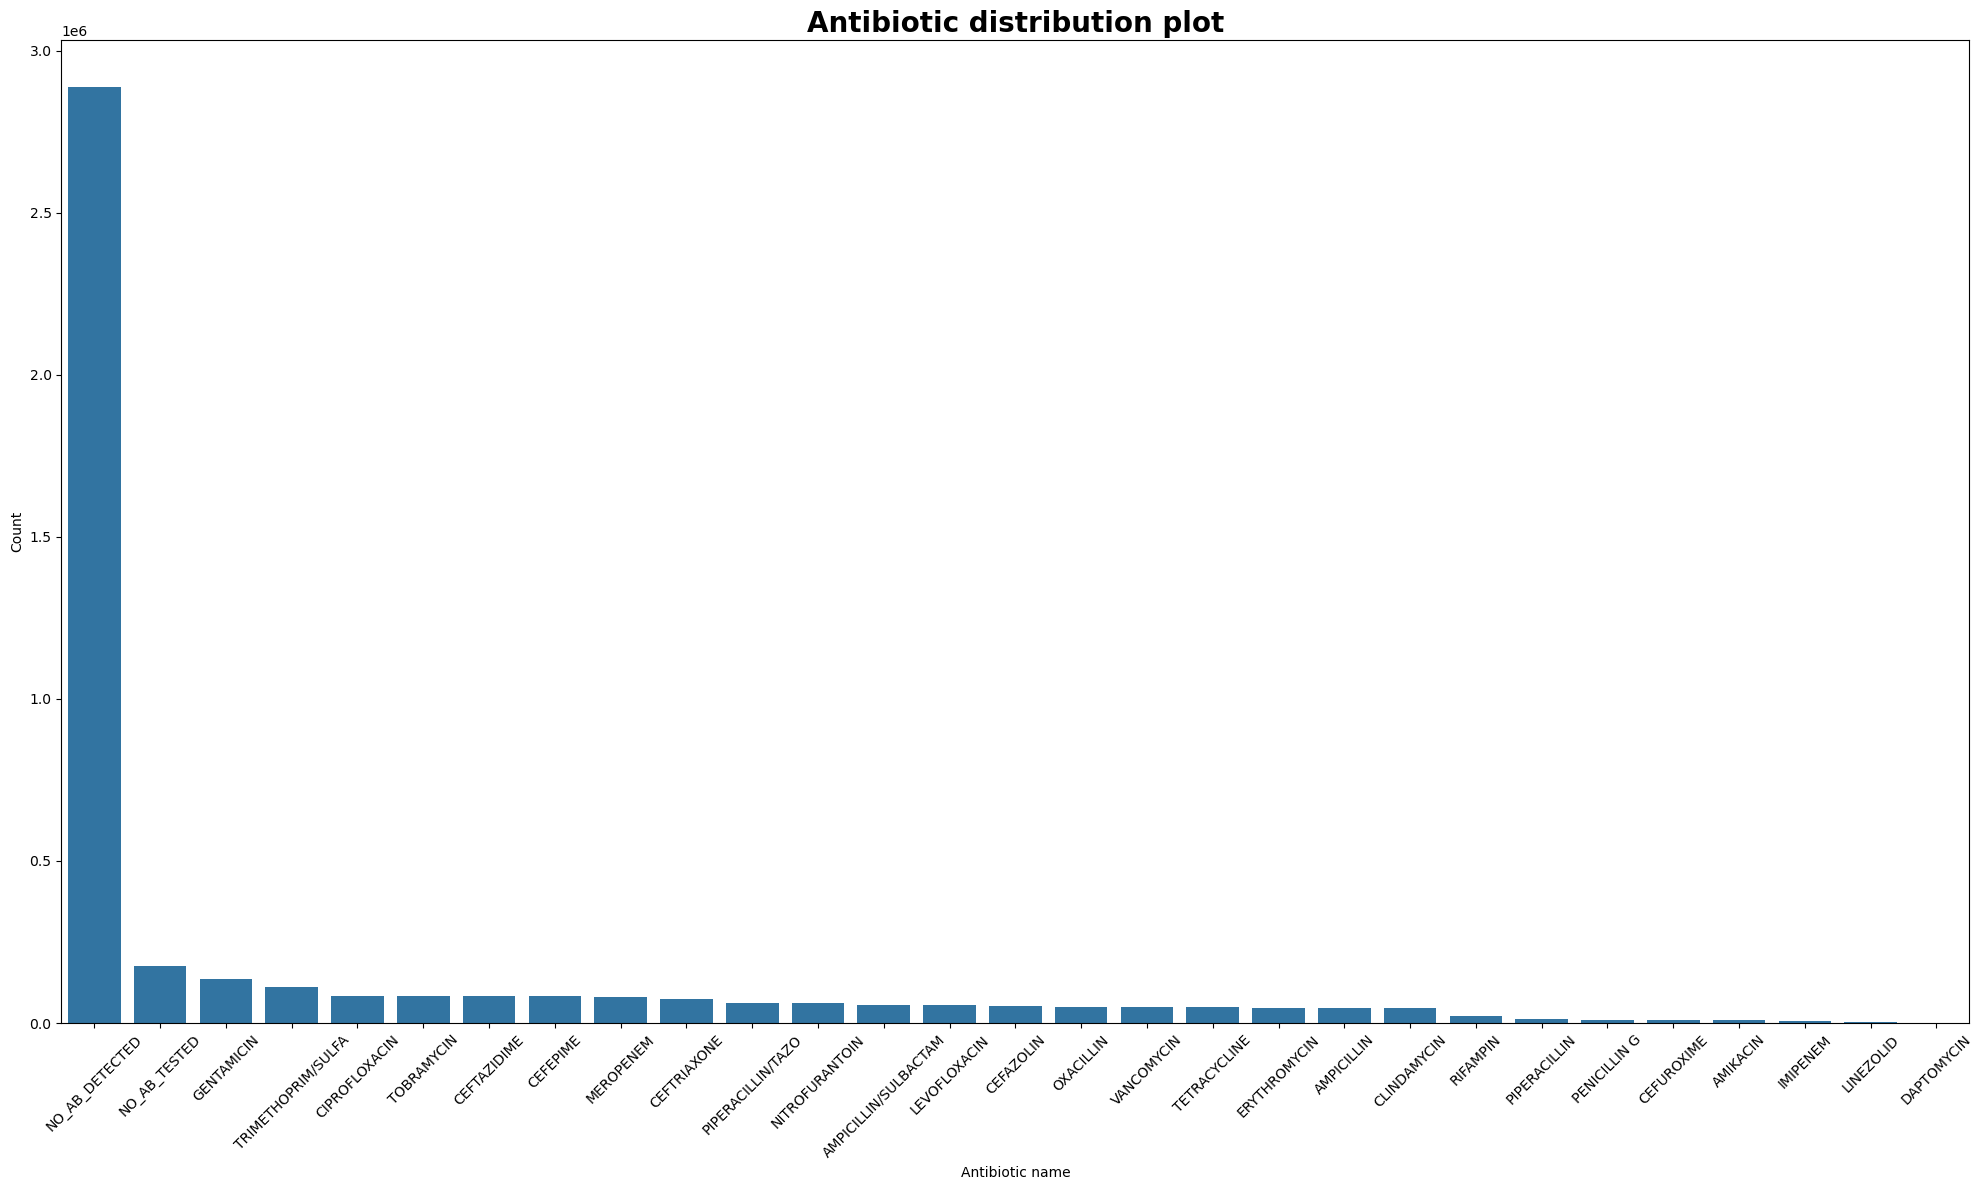

In [19]:
ab_count =joined_df['ab_name'].value_counts()

plt.figure(figsize=(20, 12))
sns.barplot(x=ab_count.index, y=ab_count.values)
plt.title("Antibiotic distribution plot", fontsize=20, fontweight="bold")
plt.xlabel("Antibiotic name")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

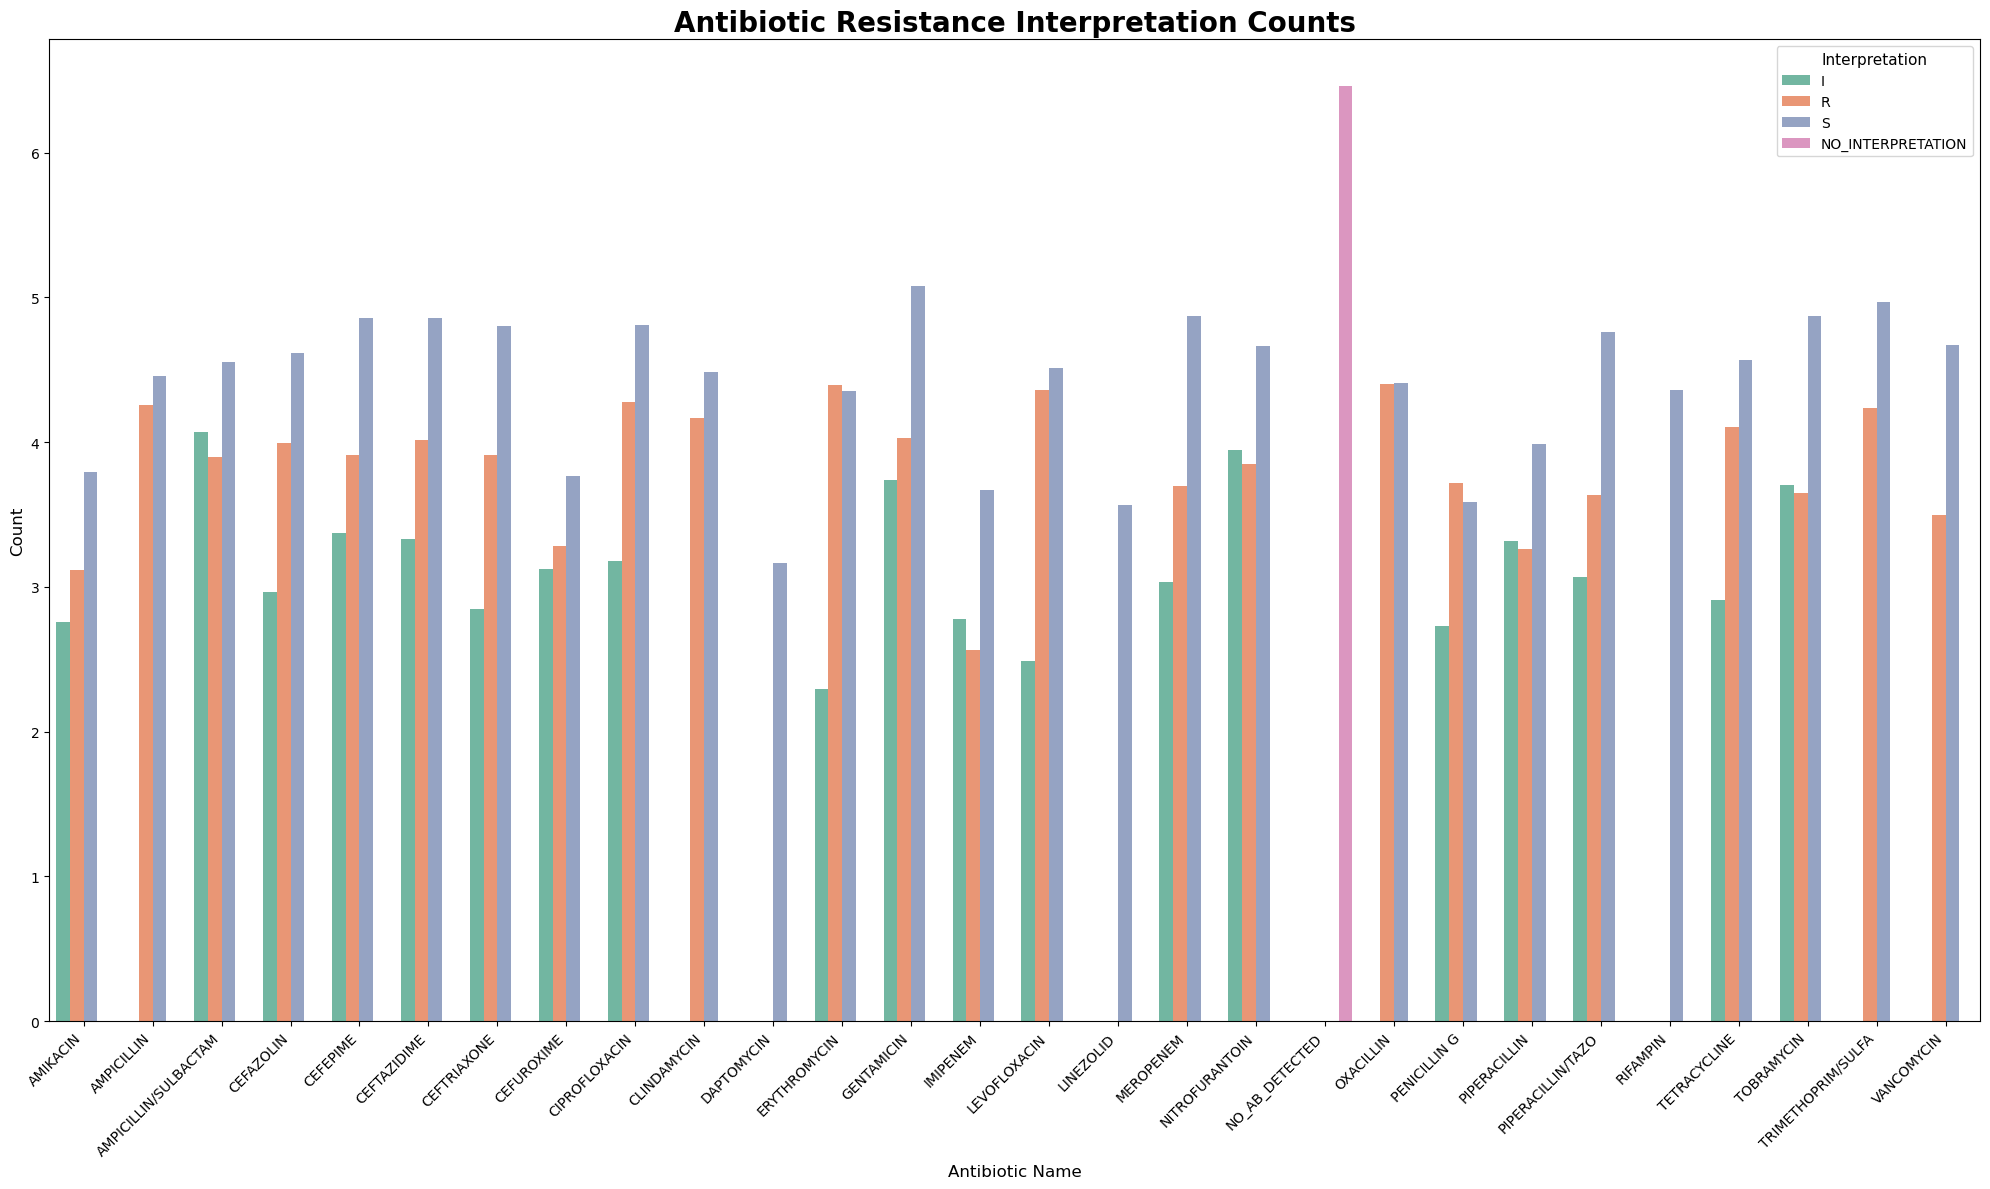

In [20]:
# Get the counts
resistant_counts = np.log10(joined_df.groupby("ab_name")['interpretation'].value_counts().replace(0, np.nan))
counts_df = resistant_counts.reset_index(name='count')

# Calculate average count for each interpretation to determine order
interpretation_avg = counts_df.groupby('interpretation')['count'].mean().sort_values(ascending=True)
sorted_interpretations = interpretation_avg.index.tolist()

# Create the plot
fig, ax = plt.subplots(figsize=(20,12))

# Create grouped barplot with sorted hue order
sns.barplot(
    data=counts_df,
    x='ab_name',
    y='count',
    hue='interpretation',
    ax=ax,
    palette='Set2',
    hue_order=sorted_interpretations
)

# Customize the plot
ax.set_title('Antibiotic Resistance Interpretation Counts', fontsize=20, fontweight='bold')
ax.set_xlabel('Antibiotic Name', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.legend(title='Interpretation', title_fontsize=11, fontsize=10)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

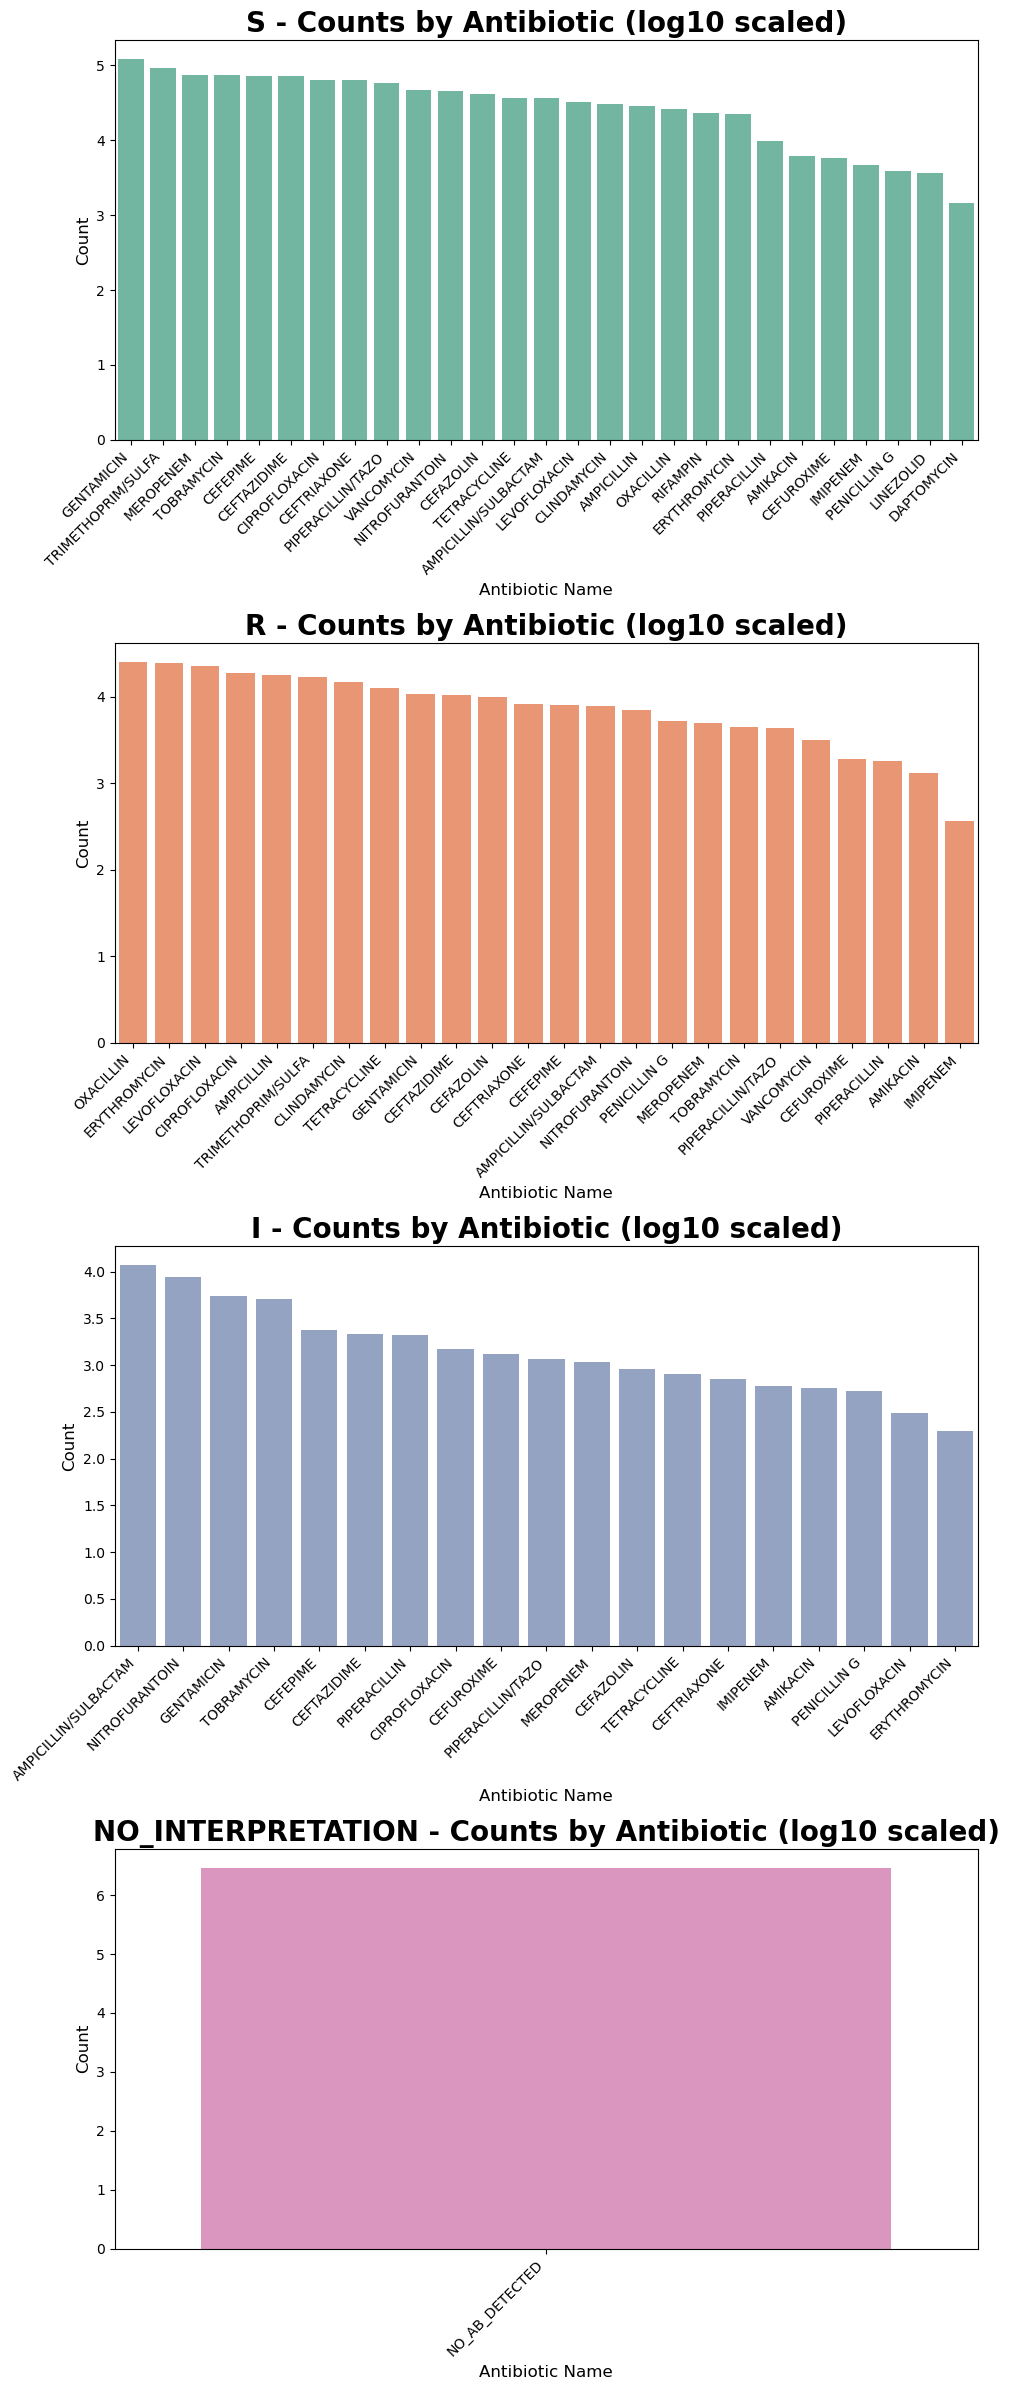

In [21]:
# Get unique interpretations
interpretations = counts_df['interpretation'].unique()
n_interpretations = len(interpretations)

# Create subplots - one for each interpretation
fig, axes = plt.subplots(n_interpretations, 1, figsize=(10,  6* n_interpretations))

# Handle case of single interpretation
if n_interpretations == 1:
    axes = [axes]

# Create a plot for each interpretation
for idx, interpretation in enumerate(interpretations):
    # Filter data for this interpretation
    subset = counts_df[counts_df['interpretation'] == interpretation]
    
    # Sort by count in descending order
    subset = subset.sort_values('count', ascending=False)
    
    # Create barplot
    sns.barplot(
        data=subset,
        x='ab_name',
        y='count',
        ax=axes[idx],
        color=sns.color_palette('Set2')[idx % 10],
        order=subset['ab_name']  # Explicitly set the order
    )
    
    # Customize the subplot
    axes[idx].set_title(f'{interpretation} - Counts by Antibiotic (log10 scaled)', 
                        fontsize=20, fontweight='bold')
    axes[idx].set_xlabel('Antibiotic Name', fontsize=12)
    axes[idx].set_ylabel('Count', fontsize=12)
    
    # Rotate x-axis labels
    axes[idx].tick_params(axis='x', rotation=45)
    plt.setp(axes[idx].xaxis.get_majorticklabels(), ha='right')

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()